# Lab: Relationships in Space and Time

Select **two distinct datasets that each contain both spatial and temporal information**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of Plotly Express figures for each question**, for a total of two research questions and four figures.

Together, each pair of figures must help answer where and when the pattern occurs. A map and a time-series plot are one useful combination; other combinations are welcome when you explain how they address both space and time.

## Learning goals

- Select and document datasets with usable location and time features.
- Ask focused questions that connect a measurement or event count to both space and time.
- Prepare dates, geographic identifiers, and summaries appropriately for the question.
- Create and compare two complementary interactive figures for each question.
- Check plotted values and ordering against the records.
- Support conclusions with evidence and explain the limitations of the data and displays.

## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.

## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.

## Select your two datasets

Each dataset needs:

- A documented publisher and feature definitions or data dictionary.
- A usable **time feature**, such as a timestamp, date, month, or year, with observations from multiple times.
- A usable **spatial feature**, such as coordinates, station locations, or named geographic areas with matching identifiers, covering multiple places or a moving object's locations.
- A quantitative measurement with known units, or event records that support a meaningful count.
- Enough usable observations to compare places and periods. A file with dates from one fixed location alone will not support a spatial comparison.

Use two distinct datasets, not two filters of the same file. Choose your own questions and records rather than reproducing a worked lecture example. The suggestions below are starting points, not required choices. You may select another documented source.

Choose manageable geographic and time ranges before downloading. A country or city name does not automatically provide coordinates; document any station lookup, geographic-code lookup, or boundary file you need. Save fixed copies in this notebook's `data` folder, preserve the original records, and use relative paths. Include supporting lookup files with your submission.

### Candidate datasets

| Candidate and source | Useful spatial and time information | Possible question and figure pair |
| --- | --- | --- |
| [USGS earthquake catalog](https://earthquake.usgs.gov/earthquakes/search/) and [CSV field definitions](https://earthquake.usgs.gov/earthquakes/feed/v1.0/csv.php) | Event time, coordinates, magnitude, and depth. Limit the dates, geographic bounds, and magnitude range; download CSV. | Where did recorded earthquakes cluster during a selected period, and how did monthly counts change? Use a point or density map and a monthly count plot. |
| [NOAA daily weather observations](https://www.ncei.noaa.gov/cdo-web/search) and [GHCNd documentation](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily) | Station identifiers, dates, temperature or precipitation, and documented station locations. Select several stations and the same time span. | How did monthly precipitation differ among selected locations during a year? Use a station map of monthly summaries and a line plot or location-by-month heatmap. |
| [EPA daily air-quality data](https://www.epa.gov/outdoor-air-quality-data/download-daily-data) and [file documentation](https://aqs.epa.gov/aqsweb/airdata/download_files.html) | Monitor or county identifiers, dates, pollutant measurements or AQI. Use one pollutant and compatible units; obtain station coordinates if making a point map. | Where and when were PM2.5 concentrations highest among selected monitors? Use a map and a time-series plot grouped by monitor. |
| [NOAA Storm Events Database](https://www.ncei.noaa.gov/access/storm-events-database/) | Event dates, states/counties, event types, and locations when reported. Start with one event type, a few states, and a limited period. | How did reported hail-event counts vary across selected counties and months? Use a county choropleth and a county-by-month heatmap. County boundaries/codes are needed for the map. |

Adapt the question to the fields actually available. Counts of reported events or monitor observations can reflect reporting and sampling effort as well as the underlying phenomenon. Do not treat missing observations as zero events or average measurements with incompatible units.

## Choose two complementary figures per question

Choose **different chart types**, not two copies that differ only in color, title, filter, or static-versus-animated display. You may reuse a useful chart type with the second dataset. An animation counts as one figure, regardless of its number of frames. Animation is optional; a well-chosen static comparison can be easier to interpret.

| Figure | Plotly Express tools | What it can help you see |
| --- | --- | --- |
| Time-series line plot | `px.line()` | How a measurement changes over time; color or separate panels can distinguish locations. Sort dates within each series before connecting points. |
| Point or bubble map | `px.scatter_geo()` or `px.scatter_map()` | Where observations occur; color and size can show quantitative values. Time can appear in hover information, filters, or animation. |
| Choropleth | `px.choropleth()` | How an area-level summary varies geographically, optionally animated by period. Match country/state codes or supply matching GeoJSON boundaries. |
| Bubble scatterplot | `px.scatter()` | How two quantitative features relate; geographic groups and time can be represented by color and animation. Explain how location is represented if this replaces a map. |
| Geographic path — an additional option | `px.line_geo()` or `px.line_map()` | A recorded route or moving object's sequence of positions. Sort within each tracked object; do not connect unrelated events into a path. |
| Spatial density map — an additional option | `px.density_map()` | Where many nearby point observations concentrate. The smoothing radius affects the appearance; this is not automatically a rate or a map of risk. |
| Location-by-time heatmap — an additional option | `px.imshow()` | Rows represent locations, columns represent ordered periods, and color represents a count or measurement. Summarize to one value per location-period first. |

Use the [Plotly map guide](https://plotly.com/python/map-configuration/), [heatmap guide](https://plotly.com/python/heatmaps/), and [animation guide](https://plotly.com/python/animations/) for examples and parameters. Tile maps need access to background tiles; geographic maps may also need internet access for boundary outlines.

### Starting patterns for additional chart types

These are **adaptation examples**, not code to run unchanged. Replace the DataFrame and feature names with yours. They do not add requirements to your four figures.

**Path of a tracked object:** only use this when consecutive rows describe the same object's movement.

```python
track_df.sort_values(['object_id', 'date'], inplace=True)
fig = px.line_geo(track_df, lat='latitude', lon='longitude',
                  color='object_id', hover_data=['date'],
                  title='Recorded paths')
fig.update_layout(height=500)
fig.show()
```

**Density of point observations:** omit `z` to give every row equal weight. Document any deliberate weighting.

```python
fig = px.density_map(events_df, lat='latitude', lon='longitude',
                     radius=15, map_style='open-street-map',
                     title='Concentration of recorded events')
fig.update_layout(height=500)
fig.show()
```

**Location-by-month heatmap:** this example uses a mean measurement. Use a sum or count only when that statistic answers your question. Missing cells remain missing unless you can establish that a zero is appropriate.

```python
observations_df['month'] = observations_df['date'].dt.to_period('M').astype(str)
monthly_df = observations_df.groupby(['location', 'month'])['value'].mean().reset_index()
grid = monthly_df.pivot(index='location', columns='month', values='value')
grid = grid.reindex(sorted(grid.columns), axis=1)
fig = px.imshow(grid, aspect='auto',
                labels={'x':'Month', 'y':'Location', 'color':'Mean value'},
                title='Mean measurement by location and month')
fig.update_layout(height=500)
fig.show()
```

### Make the comparison interpretable

Use descriptive titles, labels with units, and informative hover fields. Start with `fig.update_layout(height=500)` and adjust only if needed. Keep scales consistent when comparing frames or panels. Use a manageable number of time periods—monthly, quarterly, or yearly frames often work better than hundreds of daily frames. Explain any aggregation and retain the original dates.

For maps, confirm that geographic codes match the boundaries and that points appear in plausible places. Numeric identifiers are not quantitative measurements. A colored area or large marker does not necessarily mean greater risk: consider population, area, observation effort, and what the encoded value actually measures.

In [1]:
# Import Pandas and Plotly Express.
import pandas as pd
import plotly.express as px

## Investigation 1: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer: My question is which regions had the highest video game sales, and when annual sales peaked in each region from 1980 to 2016. I expect North America to have the highest total sales because it is the broadest market among the four region labels. I expect each region to rise from the 1980s, peak sometime in the 2000s, and then decline toward 2016. I expect Japan to peak earlier than North America and Europe, since its market developed earlier, and I expect Europe to peak a little later than North America. It is useful to consider both space and time because a region can have high total sales without being high in every year. Comparing the regions year by year shows whether a region's lead is steady or concentrated in a few years, and whether the regions peaked at the same time.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer: The dataset is Video Games Sales [1980-2020], a simplified video game sales dataset created and published on Kaggle by LWobole. The direct source is https://www.kaggle.com/datasets/bobivanleyga/video-games-sales-1980-2020. The data dictionary is the “Features” section on that same Kaggle page, which defines Name, Platform, Year, Genre, Publisher, Region, and Total Sales. I accessed the dataset on November 12, 2026. I saved the file as data/VideoGameSales.csv. No lookup or boundary files are needed because the spatial feature is a set of region labels, not coordinates or map areas.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer: One row appears to represent one game-platform title's sales in one region, not one copy sold and not one game across all regions. The four region labels are NA (North America), EU (Europe), JP (Japan), and Other. The title says the release years run from 1980 to 2020. The Kaggle page says the data came from a vgsales dataset scraped from vgchartz.com, and that Region gives sales in NA, EU, JP, and Other regions in millions of copies. The page also describes Total Sales as total worldwide sales, but because the file has one row per region, I will check whether that column is the regional value or the worldwide total when I load the data. The page does not document the scrape date or how the games were selected, so those details are undocumented.

In [2]:
# Read dataset 1 from a relative path into a descriptive DataFrame ending in _df.
# Parse the time feature as appropriate for its documented format.

# Year is already stored as an integer year, so no date parsing is needed.
# The region code "NA" means North America, so keeping it as text instead of letting Pandas read it as missing.
games_df = pd.read_csv("data/VideoGameSales.csv", keep_default_na=False)

In [3]:
# Display .head(), .tail(), and .shape in separate cells. Add cells as needed.
games_df.head()

,Name,Platform,Year,Genre,Publisher,Region,Total Sales
0,Imagine: Teacher,DS,2008,Simulation,Ubisoft,JP,0.0
1,Imagine: Wedding Designer,DS,2008,Simulation,Ubisoft,JP,0.0
2,Imagine: Babysitters,DS,2008,Simulation,Ubisoft,JP,0.0
3,Imagine: Fashion Designer New York,DS,2008,Simulation,Ubisoft,JP,0.0
4,Puzzler Collection,DS,2008,Puzzle,Ubisoft,JP,0.0


In [4]:
games_df.tail()

,Name,Platform,Year,Genre,Publisher,Region,Total Sales
65303,Mirror's Edge,PC,2009,Platform,Electronic Arts,EU,0.05
65304,The Lord of the Rings: The Battle for Middle-E...,X360,2006,Strategy,Electronic Arts,EU,0.05
65305,Mirror's Edge Catalyst,PC,2016,Platform,Electronic Arts,EU,0.03
65306,Crusader: No Remorse,PS,1996,Adventure,Electronic Arts,NA,0.03
65307,Black & White,PC,2001,Strategy,Electronic Arts,EU,0.04


In [5]:
games_df.shape

(65308, 7)

In [6]:
# Use .info() to inspect the data storage types and non-missing values.
# Count missing values in every feature.
games_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65308 entries, 0 to 65307
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         65308 non-null  object 
 1   Platform     65308 non-null  object 
 2   Year         65308 non-null  int64  
 3   Genre        65308 non-null  object 
 4   Publisher    65308 non-null  object 
 5   Region       65308 non-null  object 
 6   Total Sales  65308 non-null  float64
dtypes: float64(1), int64(1), object(5)
memory usage: 3.5+ MB


In [7]:
games_df.isnull().sum()

Name           0
Platform       0
Year           0
Genre          0
Publisher      0
Region         0
Total Sales    0
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `Name` | Game title | categorical | object | 0 |
| `Platform` | Release platform code, such as DS or PS4 | categorical | object | 0 |
| `Region` | Sales region: NA, EU, JP, or Other | categorical | object | 0 |
| `Year` | Release year | temporal | int64 | 0 |
| `Total Sales` | Sales value, millions of copies | quantitative | float64 | 0 |

Use quantitative, categorical, or temporal for feature type.

Your answer: The storage types and missing counts come from the `.info()` and `.isnull().sum()` output. All five features are complete. The `Region` column needed special handling: read normally, Pandas treats the text “NA” as a missing value, so I used `keep_default_na=False` to keep the North America rows. The `Publisher` and `Genre` columns are not used in this question, but because I read the file with `keep_default_na=False`, blank text fields such as `Publisher` stay as empty strings instead of becoming missing values, so their missing counts look lower than they would with the default settings.

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer: I will use `Region` as the geographic grouping, `Year` as the time feature, and `Total Sales` as the quantitative measurement. I will keep release years 1980–2016. The file title says it runs to 2020, but when inspecting the file, the last few years only had a small amount of games. I will sum sales across all game-platform rows within each region and year. This treats each row as that region's sales, which I will verify in the Check step by comparing a title that appears in more than one region. If the column is regional, summing gives total regional sales rather than average sales per game. I will keep the `NA`, `EU`, `JP`, and `Other` labels as text. I will not drop any rows for missing values because the five features I use are complete after reading `NA` as a region label. One limitation of this grouping is that `Other` is a residual category, not a specific place.

In [8]:
# Prepare the analysis data and summaries. Sort time values within each relevant group.
# Report the original and retained row counts and any unmatched geographic identifiers.

games_analysis_df = games_df[(games_df["Year"] >= 1980) & (games_df["Year"] <= 2016)].copy()
annual_sales_df = (games_analysis_df.groupby(["Region", "Year"], as_index=False)["Total Sales"].sum())
annual_sales_df = annual_sales_df.sort_values(["Region", "Year"])

print("Original rows:", len(games_df))
print("Rows retained for 1980-2016:", len(games_analysis_df))
print("Rows removed:", len(games_df) - len(games_analysis_df))
print("Regions:", sorted(games_analysis_df["Region"].unique()))
print("Years:", games_analysis_df["Year"].min(), "to", games_analysis_df["Year"].max())
print("Summary rows:", len(annual_sales_df))
print("\nTotal sales by region (millions of copies):")
print(annual_sales_df.groupby("Region")["Total Sales"].sum().round(2).to_string())
annual_sales_df.head()

Original rows: 65308
Rows retained for 1980-2016: 65292
Rows removed: 16
Regions: ['EU', 'JP', 'NA', 'Other']
Years: 1980 to 2016
Summary rows: 148

Total sales by region (millions of copies):
Region
EU       2409.12
JP       1284.25
NA       4333.16
Other     788.99


,Region,Year,Total Sales
0,EU,1980,0.67
1,EU,1981,1.96
2,EU,1982,1.65
3,EU,1983,0.80
4,EU,1984,2.10


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer: The file has 65,308 rows. I kept 65,292 rows from 1980–2016 and removed 16 rows outside 1980–2016. After summing, the annual summary has 148 rows: four regions times 37 years. One row in the summary represents one region in one release year, and `Total Sales` is the total sales of all game-platform records in that region and year, in millions of copies.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer: I will use a line plot and a region-by-year heatmap. The line plot puts release year on the horizontal axis and annual sales on the vertical axis, with one colored line per region so it should make the timing of each region's rise and peak easy to compare. The heatmap puts years on the horizontal axis and regions on the vertical axis, with color showing annual sales so it should make the full region-year pattern and the empty years easier to see at once. The line plot is better for comparing trends, and the heatmap is better for checking individual region-year cells and gaps.

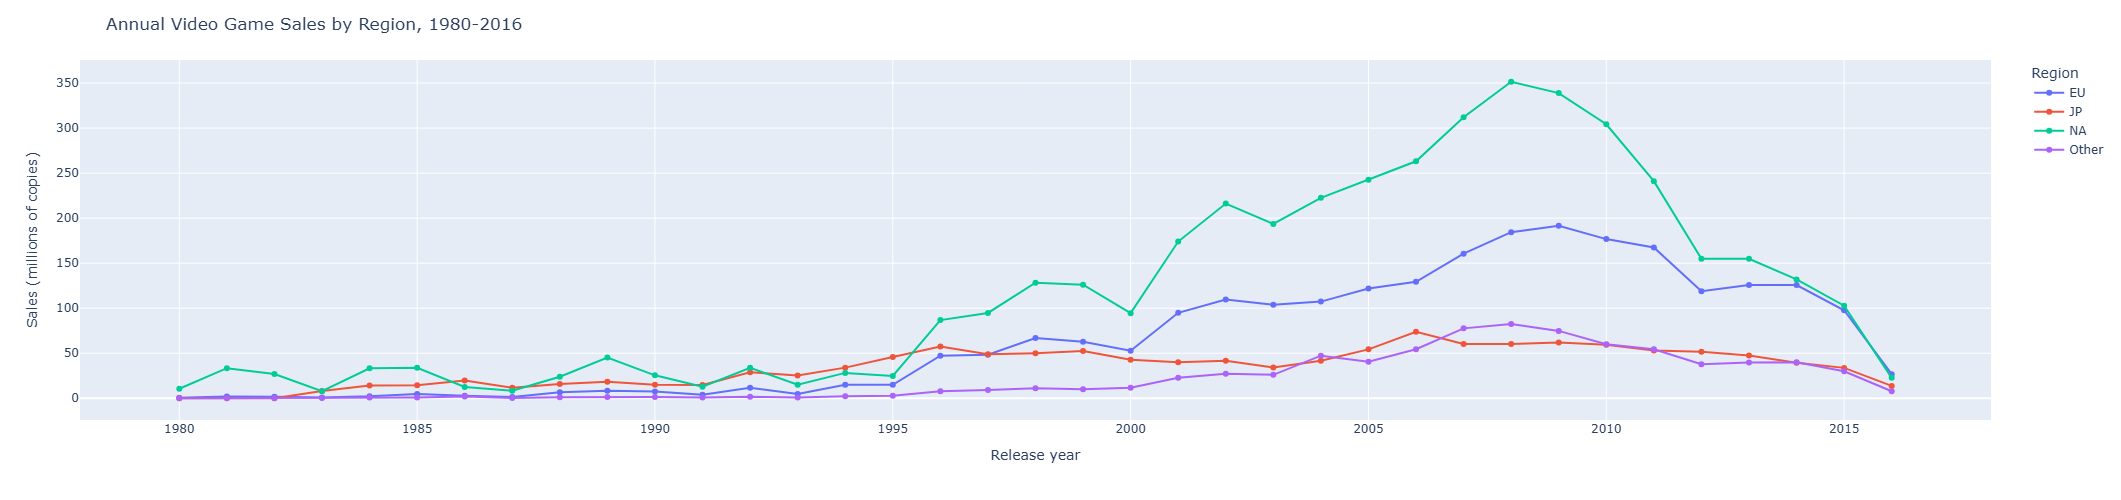

,Region,Year,Total Sales
29,EU,2009,191.59
63,JP,2006,73.73
102,NA,2008,351.44
139,Other,2008,82.39


In [9]:
# Create Figure 1 with a descriptive title, units, useful hover fields, and suitable dimensions.
# If animated, use chronological frames and fixed scales.
fig = px.line(annual_sales_df, x="Year", y="Total Sales", color="Region", markers=True,
              labels={"Year": "Release year",
                      "Total Sales": "Sales (millions of copies)",
                      "Region": "Region"})
fig.update_layout(title="Annual Video Game Sales by Region, 1980-2016", height=500)
fig.show()

annual_sales_df.loc[annual_sales_df.groupby("Region")["Total Sales"].idxmax()]

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer: The line plot shows that North America has the highest sales for most of the period and peaks at 351.44 million copies in 2008. Europe peaks at 191.59 million in 2009, Japan peaks at 73.73 million in 2006, and Other peaks at 82.39 million in 2008. All four regions rise from the 1980s, reach their highest values in the 2000s, and then fall toward 2016. Japan's peak comes earlier than the others, and Europe's peak comes one year after North America's. The lines are far apart in the 2000s, when North America is well above the other regions.

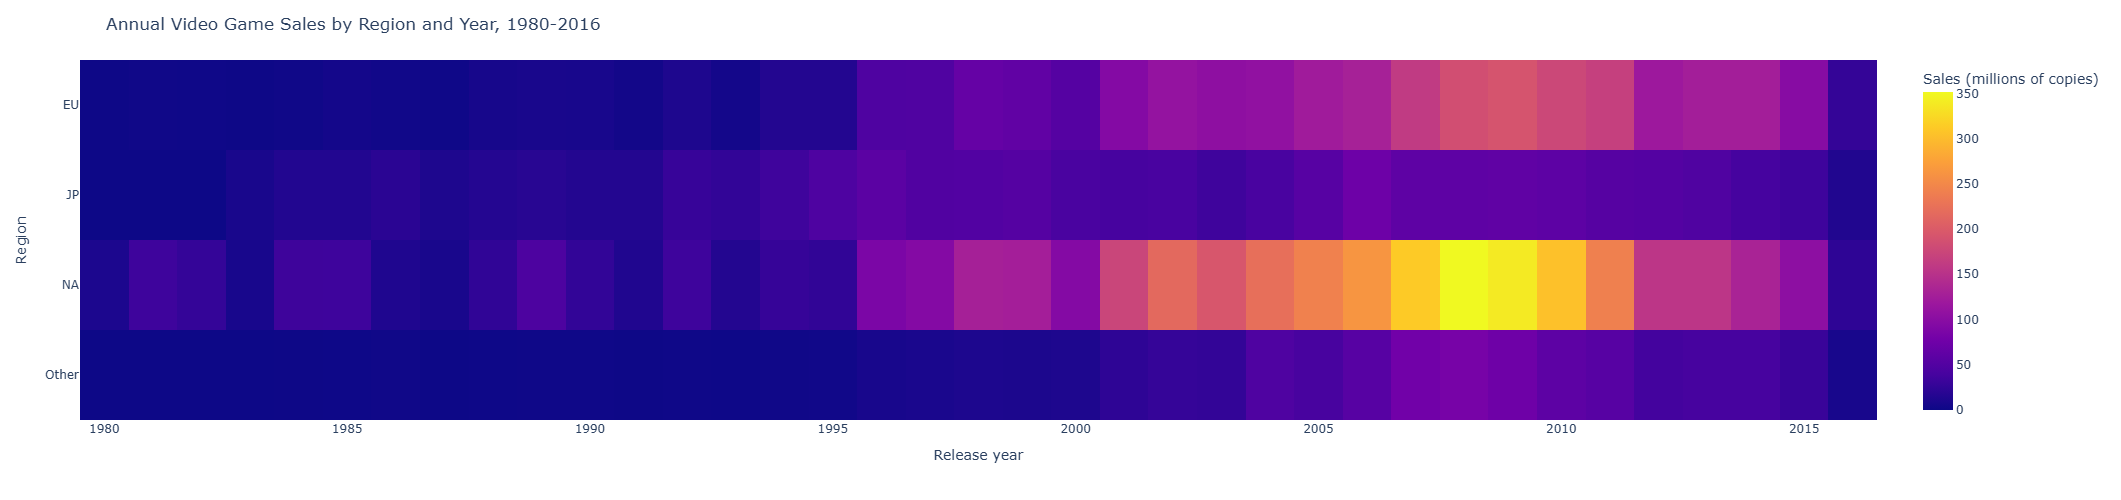

,Region,Year,Total Sales
102,NA,2008,351.44
103,NA,2009,338.85
101,NA,2007,312.05
104,NA,2010,304.24
100,NA,2006,263.12


In [10]:
# Create Figure 2 using a different chart type to answer the same research question.
# Label any aggregation or transformation.
sales_grid = annual_sales_df.pivot(index="Region", columns="Year", values="Total Sales")
sales_grid = sales_grid.reindex(sorted(sales_grid.columns), axis=1)

fig = px.imshow(sales_grid, aspect="auto",labels={"x": "Release year", "y": "Region", "color": "Sales (millions of copies)"})
fig.update_layout(title="Annual Video Game Sales by Region and Year, 1980-2016", height=500)
fig.show()

annual_sales_df.nlargest(5, "Total Sales")

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer: The heatmap adds the full region-year grid. It shows that the largest cells are all in North America: 351.44 million in 2008, 338.85 million in 2009, 312.05 million in 2007, and 304.24 million in 2010. It also makes the timing clear: North America's darkest block runs from about 2006 to 2011, Europe's darkest cells are around 2008–2011, and Japan's darkest cells are earlier, around 2005–2008. The heatmap also shows the nearly empty columns after 2016, which the line plot compresses at the right edge. The line plot makes the shape of each region's rise and fall easier to follow, while the heatmap makes the relative size of each region-year and the gaps easier to compare.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [11]:
# Verify selected plotted values against records or summaries.
# Check the relevant time order, geographic match, or unusual observation.
print("NA 2008 from original rows:", round(games_df.query("Region == 'NA' and Year == 2008")["Total Sales"].sum(), 2))
print("EU 2009 from original rows:", round(games_df.query("Region == 'EU' and Year == 2009")["Total Sales"].sum(), 2))
print("Summary value for NA 2008:", round(annual_sales_df.query("Region == 'NA' and Year == 2008")["Total Sales"].iloc[0], 2))
print("Summary value for EU 2009:", round(annual_sales_df.query("Region == 'EU' and Year == 2009")["Total Sales"].iloc[0], 2))
print("Years increase within each region:", annual_sales_df.groupby("Region")["Year"].apply(lambda s: s.is_monotonic_increasing).to_dict())
print("Rows in 2017-2020:", len(games_df[games_df["Year"] >= 2017]))
print("Heatmap grid shape:", sales_grid.shape)
print("Rows with Region read as missing by default:", pd.read_csv("data/VideoGameSales.csv", usecols=["Region"])["Region"].isna().sum())
print("Wii Sports rows:")
print(games_df[games_df["Name"] == "Wii Sports"][["Name", "Platform", "Year", "Region", "Total Sales"]].to_string(index=False))

NA 2008 from original rows: 351.44
EU 2009 from original rows: 191.59
Summary value for NA 2008: 351.44
Summary value for EU 2009: 191.59
Years increase within each region: {'EU': True, 'JP': True, 'NA': True, 'Other': True}
Rows in 2017-2020: 16
Heatmap grid shape: (4, 37)
Rows with Region read as missing by default: 16327
Wii Sports rows:
      Name Platform  Year Region  Total Sales
Wii Sports      Wii  2006     NA        41.49
Wii Sports      Wii  2006     EU        29.02
Wii Sports      Wii  2006     JP         3.77
Wii Sports      Wii  2006  Other         8.46


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer: I checked North America in 2008 and Europe in 2009. The original rows sum to 351.44 million copies for NA 2008 and 191.59 million for EU 2009, and the summary table gives the same two values, so the plotted peaks agree with the records. The Wii Sports rows show 41.49 million in NA, 29.02 million in EU, 3.77 million in JP, and 8.46 million in Other, so `Total Sales` is the value for that row's region, not the worldwide total. The years increase within each region, so the lines are drawn in chronological order. The unusual high is North America in 2008, which is far above every other region-year; it is a real sum of many game-platform rows, not a single record. The apparent gap is 2017–2020, which has only 16 rows in the whole file, so I stopped the analysis at 2016. I also found a reading problem: Pandas treats the region code “NA” as a missing value by default, which would have dropped 16,327 North America rows. Reading the file with `keep_default_na=False` preserved them, and the region counts then matched the four labels.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer: My question was which regions had the highest video game sales and when annual sales peaked in each region from 1980 to 2016. North America had the highest total sales by a wide margin: 4,333.2 million copies, compared with 2,409.1 million for Europe, 1,284.3 million for Japan, and 789.0 million for Other. North America also had the highest single year, 351.44 million copies in 2008. The regions did not peak together: Japan peaked in 2006 at 73.73 million, North America and Other both peaked in 2008 at 351.44 million and 82.39 million, and Europe peaked in 2009 at 191.59 million. All four regions rose from the 1980s and fell after their peaks, so the 2000s were the strongest period in this file. This supports my prediction that North America would lead and that the peaks would fall in the 2000s, and it also supports my guess that Japan would peak earlier and Europe a little later. The main surprise is how far North America's 2008 value exceeds the other regions.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: First, sales are assigned to the game's release year, not the year the copies were sold. A game released in 2008 may have kept selling in later years, so the annual values are not the same as yearly sales revenue. The file is also a snapshot with an unknown license and no documented scrape date, and it may leave out small, digital-only, or unlisted games, so the totals are not a complete count of the market. Second, the region labels are coarse. `Other` is a residual group rather than a specific place, and the four labels do not match countries or map boundaries. The line plot makes the rise and fall of each region easy to compare, but it hides how many games contribute to each year and compresses the nearly empty years after 2016. The heatmap shows the region-year cells and the gaps, but it also hides the number of releases behind each cell. Neither figure adjusts for the number of games released, so a region-year with more releases will tend to have higher total sales.

## Investigation 2: Your dataset and research question

### Step 1: Question

Ask one focused question that depends on **both where and when** something occurs. Name the measurement or count, the places, and the period. Record a prediction before producing the figures.

**What is your research question, and what do you predict? Why is it useful to consider both space and time?**

Your answer: My question is in which states and months used vehicles sold furthest above or below their Manheim Market Report (MMR) value between December 2014 and June 2015. I expect most state-month medians to be close to MMR, within a few percent, because MMR is an estimate of market value. I expect a few states to sit consistently above or below the estimate, and I expect more spread in months or states with fewer sales. I do not expect a strong seasonal pattern over this short window, but I expect some month-to-month movement. It is useful to consider both space and time because a state can be above MMR overall while being above it in only one month. The map shows where the differences are, and the line plot shows when they occur.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Parse dates when needed and preserve geographic identifiers appropriately.

**Give the dataset title, publisher, direct source URL, dictionary reference, and access date. Identify your saved file and any lookup or boundary files.**

Your answer: The dataset is the Vehicle Sales and Market Trends Dataset, created and published on Kaggle by Syed Anwar. The direct source is https://www.kaggle.com/datasets/syedanwarafridi/vehicle-sales-data. The data dictionary is the dataset description and column list on that same Kaggle page, which defines the vehicle details, state of registration, condition, odometer, MMR value, selling price, and sale date. I accessed the dataset on November 12, 2026. I saved the file as data/car_prices.csv. The license is listed as MIT. No lookup or boundary files are needed because the state codes match Plotly's built-in USA-states boundaries.

**What does one row represent? Which places and dates are covered, and how were the observations collected?**

Your answer: One row represents one vehicle sale at auction, not one vehicle over its lifetime and not one state-month summary. The `state` field is the state of registration, `saledate` is the sale date, `sellingprice` is the sale price in U.S. dollars, and `mmr` is the Manheim Market Report estimated market value in U.S. dollars. The page describes sales transactions from various U.S. states, but it does not document a complete state list or an exact date range. I selected the continuous December 2014–June 2015 window for this question and will confirm the observed coverage after loading the file. The page does not explain how the auctions were selected, so the file should not be treated as a random sample of all U.S. used-car sales.

In [12]:
# Read dataset 2 from a relative path into a descriptive DataFrame ending in _df.
# Parse the time feature as appropriate for its documented format.
cars_df = pd.read_csv("data/car_prices.csv")
cars_df["saledate"] = pd.to_datetime(cars_df["saledate"].str.split(" GMT").str[0], format="%a %b %d %Y %H:%M:%S", errors="coerce")

In [13]:
# Display .head(), .tail(), and .shape in separate cells. Add cells as needed.
cars_df.head()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
0,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg566472,ca,5.0,16639.0,white,black,kia motors america inc,20500.0,21500.0,2014-12-16 12:30:00
1,2015,Kia,Sorento,LX,SUV,automatic,5xyktca69fg561319,ca,5.0,9393.0,white,beige,kia motors america inc,20800.0,21500.0,2014-12-16 12:30:00
2,2014,BMW,3 Series,328i SULEV,Sedan,automatic,wba3c1c51ek116351,ca,45.0,1331.0,gray,black,financial services remarketing (lease),31900.0,30000.0,2015-01-15 04:30:00
3,2015,Volvo,S60,T5,Sedan,automatic,yv1612tb4f1310987,ca,41.0,14282.0,white,black,volvo na rep/world omni,27500.0,27750.0,2015-01-29 04:30:00
4,2014,BMW,6 Series Gran Coupe,650i,Sedan,automatic,wba6b2c57ed129731,ca,43.0,2641.0,gray,black,financial services remarketing (lease),66000.0,67000.0,2014-12-18 12:30:00


In [14]:
cars_df.tail()

,year,make,model,trim,body,transmission,vin,state,condition,odometer,color,interior,seller,mmr,sellingprice,saledate
558832,2015,Kia,K900,Luxury,Sedan,NaN,knalw4d4xf6019304,in,45.0,18255.0,silver,black,avis corporation,35300.0,33000.0,2015-07-09 07:00:00
558833,2012,Ram,2500,Power Wagon,Crew Cab,automatic,3c6td5et6cg112407,wa,5.0,54393.0,white,black,i -5 uhlmann rv,30200.0,30800.0,2015-07-08 09:30:00
558834,2012,BMW,X5,xDrive35d,SUV,automatic,5uxzw0c58cl668465,ca,48.0,50561.0,black,black,financial services remarketing (lease),29800.0,34000.0,2015-07-08 09:30:00
558835,2015,Nissan,Altima,2.5 S,sedan,automatic,1n4al3ap0fc216050,ga,38.0,16658.0,white,black,enterprise vehicle exchange / tra / rental / t...,15100.0,11100.0,2015-07-09 06:45:00
558836,2014,Ford,F-150,XLT,SuperCrew,automatic,1ftfw1et2eke87277,ca,34.0,15008.0,gray,gray,ford motor credit company llc pd,29600.0,26700.0,2015-05-28 05:30:00


In [15]:
cars_df.shape

(558837, 16)

In [16]:
# Use .info() to inspect the data storage types and non-missing values.
# Count missing values in every feature.
cars_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 558837 entries, 0 to 558836
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   year          558837 non-null  int64         
 1   make          548536 non-null  object        
 2   model         548438 non-null  object        
 3   trim          548186 non-null  object        
 4   body          545642 non-null  object        
 5   transmission  493485 non-null  object        
 6   vin           558833 non-null  object        
 7   state         558837 non-null  object        
 8   condition     547017 non-null  float64       
 9   odometer      558743 non-null  float64       
 10  color         558088 non-null  object        
 11  interior      558088 non-null  object        
 12  seller        558837 non-null  object        
 13  mmr           558799 non-null  float64       
 14  sellingprice  558825 non-null  float64       
 15  saledate      558

In [17]:
cars_df.isnull().sum()

year                0
make            10301
model           10399
trim            10651
body            13195
transmission    65352
vin                 4
state               0
condition       11820
odometer           94
color             749
interior          749
seller              0
mmr                38
sellingprice       12
saledate           38
dtype: int64

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `state` | State of registration, two-letter U.S. code | categorical | object | 0 |
| `saledate` | Sale date and time; parsed to a datetime | temporal | datetime64[ns] | 38 |
| `sellingprice` | Sale price, U.S. dollars | quantitative | float64 | 12 |
| `mmr` | Manheim Market Report estimated value, U.S. dollars | quantitative | float64 | 38 |

Use quantitative, categorical, or temporal for feature type.

Your answer: The storage types and missing counts come from `.info()` and `.isnull().sum()` after parsing `saledate`. The table reports missing counts for the whole file; the preparation step removes rows with missing or unusable values along with rows that have invalid state codes. The file has other vehicle features such as year, make, model, condition, and odometer, but this question uses only the sale location, sale month, sale price, and MMR value.

**Which observations and features will you use? Explain your time periods, geographic grouping, filtering, missing-value decisions, and any counts, means, sums, or rates.**

Your answer: I will use `state` as the geographic grouping, `saledate` as the time feature, and the percent difference between `sellingprice` and `mmr` as the quantitative measurement. For each sale I will calculate `(sellingprice - mmr) / mmr * 100`, so a positive value means the vehicle sold above its MMR estimate and a negative value means it sold below. I will keep only valid two-letter U.S. state codes, drop rows with a missing or unusable date, price, or MMR, and keep the continuous December 2014–June 2015 window. I will check each month's record count and exclude any month with clearly incomplete coverage, then document that exclusion in the next answer. I will summarize each state-month with the median percent difference and require at least 30 sales, because a median from a handful of sales is unstable. One analyzed observation is one state-month summary, not one vehicle sale.

In [18]:
# Prepare the analysis data and summaries. Sort time values within each relevant group.
# Report the original and retained row counts and any unmatched geographic identifiers.
us_states = {
    "al", "ak", "az", "ar", "ca", "co", "ct", "de", "dc", "fl", "ga",
    "hi", "id", "il", "in", "ia", "ks", "ky", "la", "me", "md", "ma",
    "mi", "mn", "ms", "mo", "mt", "ne", "nv", "nh", "nj", "nm", "ny",
    "nc", "nd", "oh", "ok", "or", "pa", "ri", "sc", "sd", "tn", "tx",
    "ut", "vt", "va", "wa", "wv", "wi", "wy"
}

cars_df["state"] = cars_df["state"].str.strip().str.lower()

cars_state_df = cars_df[cars_df["state"].isin(us_states)].copy()
cars_clean_df = cars_state_df.dropna(subset=["saledate", "sellingprice", "mmr"])
cars_clean_df = cars_clean_df[(cars_clean_df["sellingprice"] > 0) & (cars_clean_df["mmr"] > 0)]
cars_clean_df["month"] = cars_clean_df["saledate"].dt.to_period("M").astype(str)
cars_clean_df["pct_diff_mmr"] = ((cars_clean_df["sellingprice"] - cars_clean_df["mmr"]) / cars_clean_df["mmr"]) * 100

cars_window_df = cars_clean_df[cars_clean_df["month"].between("2014-12", "2015-06")].copy()
cars_analysis_df = cars_window_df[cars_window_df["month"] != "2015-04"].copy()

monthly_state_df = (cars_analysis_df
                    .groupby(["state", "month"])
                    .agg(median_pct_diff=("pct_diff_mmr", "median"),
                         sales=("pct_diff_mmr", "size"))
                    .reset_index())
monthly_state_df = monthly_state_df[monthly_state_df["sales"] >= 30]
monthly_state_df = monthly_state_df.sort_values(["month", "state"])

invalid_state_counts = cars_df.loc[~cars_df["state"].isin(us_states), "state"].value_counts()

print("Original rows:", len(cars_df))
print("Rows with a valid U.S. state:", len(cars_state_df))
print("Rows removed for state:", len(cars_df) - len(cars_state_df))
print("Rows with usable date, price, and MMR:", len(cars_clean_df))
print("Rows removed for date, price, or MMR:", len(cars_state_df) - len(cars_clean_df))
print("Rows in Dec 2014-Jun 2015:", len(cars_window_df))
print("Rows removed outside that window:", len(cars_clean_df) - len(cars_window_df))
print("Rows removed for April 2015:", len(cars_window_df) - len(cars_analysis_df))
print("Rows retained:", len(cars_analysis_df))
print("Rows removed in total:", len(cars_df) - len(cars_analysis_df))
print("States retained:", cars_analysis_df["state"].nunique())
print("Months retained:", sorted(cars_analysis_df["month"].unique()))
print("State-month cells with at least 30 sales:", len(monthly_state_df))

print("\nNon-U.S. two-letter state codes:")
print(invalid_state_counts[invalid_state_counts.index.str.len() == 2].to_string())
print("Rows with a VIN in the state column:", invalid_state_counts[invalid_state_counts.index.str.len() > 2].sum())

print("\nAll months in the December 2014-June 2015 window, before excluding April:")
print(cars_window_df.groupby("month")
      .agg(sales=("pct_diff_mmr", "size"), median_pct_diff=("pct_diff_mmr", "median"))
      .round(2).to_string())

print("\nMedian percent difference from MMR by retained month:")
print(cars_analysis_df.groupby("month")["pct_diff_mmr"].median().round(2).to_string())
print("\nOverall median percent difference:", round(cars_analysis_df["pct_diff_mmr"].median(), 2))
monthly_state_df.head()

Original rows: 558837
Rows with a valid U.S. state: 550410
Rows removed for state: 8427
Rows with usable date, price, and MMR: 550398
Rows removed for date, price, or MMR: 12
Rows in Dec 2014-Jun 2015: 548916
Rows removed outside that window: 1482
Rows removed for April 2015: 1420
Rows retained: 547496
Rows removed in total: 11341
States retained: 33
Months retained: ['2014-12', '2015-01', '2015-02', '2015-03', '2015-05', '2015-06']
State-month cells with at least 30 sales: 175

Non-U.S. two-letter state codes:
state
on    3442
pr    2725
qc    1245
ab     928
ns      61
Rows with a VIN in the state column: 26

All months in the December 2014-June 2015 window, before excluding April:
          sales  median_pct_diff
month                           
2014-12   52813            -1.23
2015-01  138377            -0.65
2015-02  161015             0.00
2015-03   45694             0.40
2015-04    1420           -19.38
2015-05   51544            -1.42
2015-06   98053            -0.38

Median pe

,state,month,median_pct_diff,sales
2,az,2014-12,-0.120482,1398
8,ca,2014-12,0.743505,10628
14,co,2014-12,-0.591716,839
20,fl,2014-12,-1.843318,6823
26,ga,2014-12,0.000000,2449


**How many records were removed from the dataset? Explain why, and state what one row represents after any aggregation.**

Your answer: The file has 558,837 rows. I removed 8,427 rows with a non-U.S. state code: 8,401 rows with Canadian or Puerto Rico codes (ON 3,442, PR 2,725, QC 1,245, AB 928, and NS 61) and 26 rows with a VIN in the `state` column. I removed another 12 rows with a missing or unusable date, price, or MMR value. Restricting to December 2014–June 2015 removed 1,482 rows outside of that window. I then removed the 1,420 April 2015 rows because April has only 1,420 sales and a median about 19.4% below MMR, which looks like incomplete coverage rather than a real market shift. In total, 11,341 rows were removed and 547,496 remained. After aggregation, one row represents one state-month with at least 30 sales, and there are 175 such cells from 33 states. The monthly medians across the retained sales range from -1.42% in May 2015 to 0.40% in March 2015, and the overall median is -0.41%.

### Step 3: Evidence

Create two different Plotly Express figure types that answer this same question. Together they must display the spatial and temporal patterns. Use the prepared data consistently and explain any difference in coverage between the figures.

**Which two chart types will you use, and what part of the question should each make easier to answer? Specify the time, location, and quantitative encodings.**

Your answer: I will use an animated choropleth and a line plot. The choropleth colors each state by its median percent difference from MMR, with month as the animation frame and a fixed diverging color range centered on zero; red means the state sold above MMR and blue means below. It should make the geographic pattern and the month-to-month changes easy to see. The line plot puts sale month on the horizontal axis and median percent difference on the vertical axis, with one line per selected state; it should make the direction and size of each state's month-to-month movement easier to compare. The choropleth is better for where, and the line plot is better for when and for comparing a few states directly.

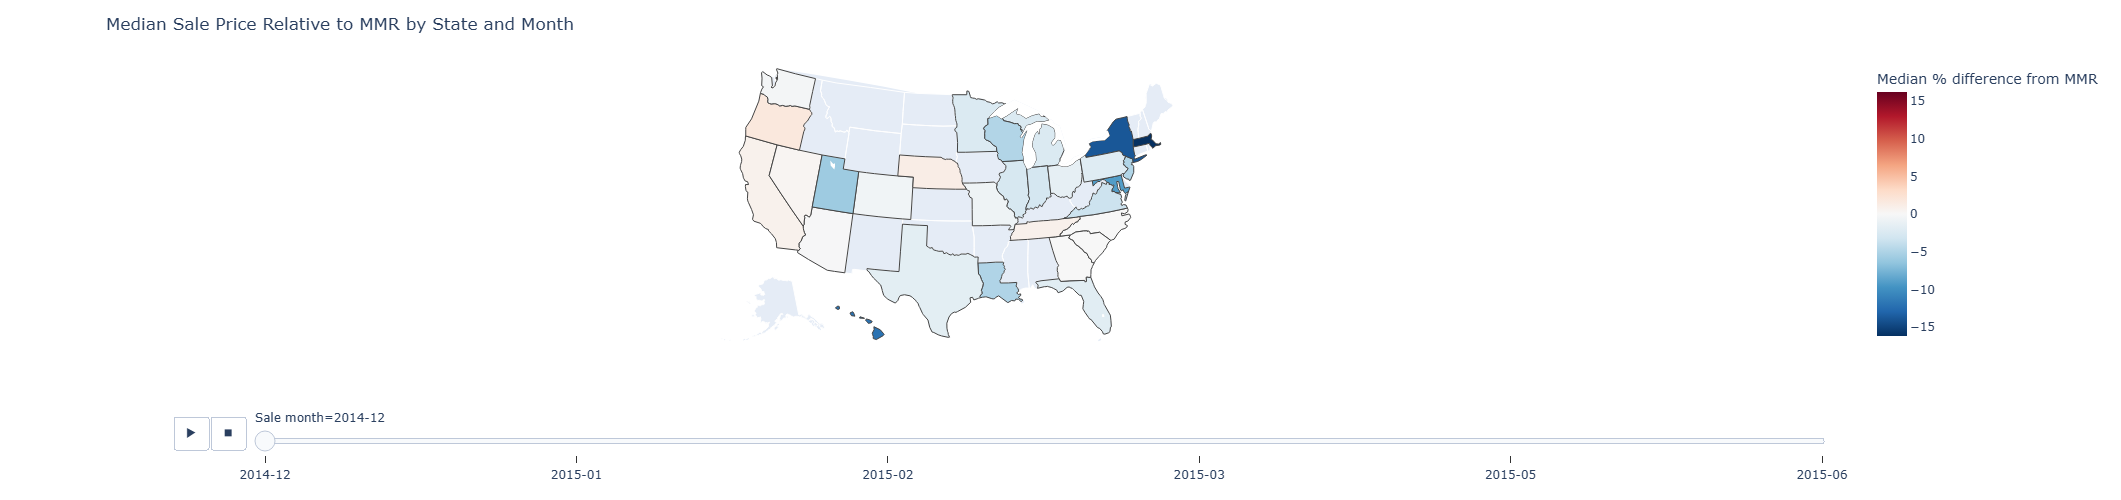

Largest positive medians:
state   month  median_pct_diff  sales
   wa 2015-03             3.59    494
   wa 2015-02             3.44   2302
   nv 2015-03             2.90    785
   sc 2015-06             2.71    646
   nc 2015-03             2.63   2948

Largest negative medians:
state   month  median_pct_diff  sales
   ma 2014-12           -16.20    423
   ny 2014-12           -13.85   1076
   hi 2014-12           -12.05    107
   ma 2015-01           -11.48   1699
   ma 2015-02           -11.03   1573


In [19]:
# Create Figure 1 with a descriptive title, units, useful hover fields, and suitable dimensions.
# If animated, use chronological frames and fixed scales.
map_df = monthly_state_df.assign(state=monthly_state_df["state"].str.upper())
color_limit = max(abs(monthly_state_df["median_pct_diff"].min()), abs(monthly_state_df["median_pct_diff"].max()))

fig = px.choropleth(
    map_df,
    locations="state",
    locationmode="USA-states",
    scope="usa",
    color="median_pct_diff",
    animation_frame="month",
    hover_name="state",
    hover_data={"sales": True, "median_pct_diff": ":.2f"},
    range_color=[-color_limit, color_limit],
    color_continuous_scale="RdBu_r",
    labels={"median_pct_diff": "Median % difference from MMR",
            "month": "Sale month",
            "state": "State",
            "sales": "Sales"}
)
fig.update_layout(title="Median Sale Price Relative to MMR by State and Month", height=500)
fig.show()

print("Largest positive medians:")
print(monthly_state_df.nlargest(5, "median_pct_diff")[["state", "month", "median_pct_diff", "sales"]].round(2).to_string(index=False))
print("\nLargest negative medians:")
print(monthly_state_df.nsmallest(5, "median_pct_diff")[["state", "month", "median_pct_diff", "sales"]].round(2).to_string(index=False))

**What does Figure 1 show? Describe a pattern and record at least one value with its place, time, and units or count.**

Your answer: The choropleth shows that most state-month cells are close to zero, with pale colors across much of the map. The largest positive median is Washington in March 2015, at 3.59% above MMR with 494 sales, followed by Washington in February 2015 at 3.44% with 2,302 sales and Nevada in March 2015 at 2.90% with 785 sales. The largest negative median is Massachusetts in December 2014, at 16.20% below MMR with 423 sales, followed by New York in December 2014 at 13.85% below with 1,076 sales and Hawaii in December 2014 at 12.05% below with 107 sales. The map also shows that some states are uncolored in some months, either because they have no records or because they have fewer than 30 sales. The animation makes the December 2014 cluster of large negative values in the Northeast and Hawaii visible, and it shows that the positive values are concentrated in a few western and southeastern states in early 2015.

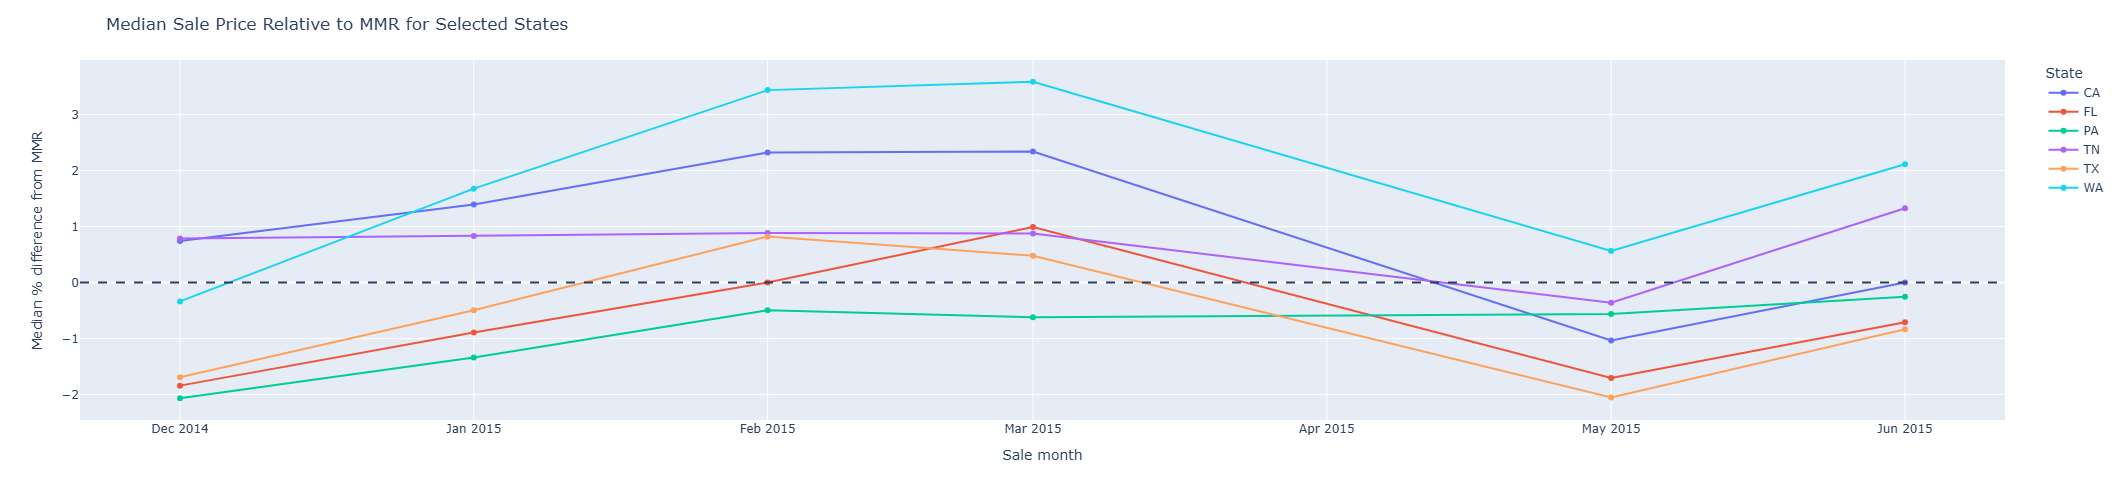

state,CA,FL,PA,TN,TX,WA
month,,,,,,
2014-12,0.74,-1.84,-2.07,0.79,-1.69,-0.34
2015-01,1.39,-0.89,-1.34,0.83,-0.50,1.68
2015-02,2.33,0.00,-0.50,0.88,0.82,3.44
2015-03,2.34,0.99,-0.62,0.88,0.48,3.59
2015-05,-1.03,-1.71,-0.56,-0.36,-2.05,0.56
2015-06,0.00,-0.71,-0.26,1.33,-0.84,2.11


In [20]:
# Create Figure 2 using a different chart type to answer the same research question.
# Label any aggregation or transformation.
selected_states = ["ca", "fl", "tx", "pa", "tn", "wa"]
line_df = monthly_state_df[monthly_state_df["state"].isin(selected_states)].copy()
line_df["state"] = line_df["state"].str.upper()
line_df["month_start"] = pd.to_datetime(line_df["month"] + "-01")
line_df = line_df.sort_values(["state", "month_start"])

fig = px.line(
    line_df,
    x="month_start",
    y="median_pct_diff",
    color="state",
    markers=True,
    labels={"month_start": "Sale month",
            "median_pct_diff": "Median % difference from MMR",
            "state": "State"}
)
fig.update_layout(title="Median Sale Price Relative to MMR for Selected States", height=500)
fig.add_hline(y=0, line_dash="dash")
fig.update_xaxes(dtick="M1", tickformat="%b %Y")
fig.show()

line_df.pivot(index="month", columns="state", values="median_pct_diff").round(2)

**What does Figure 2 add? Record at least one value with its place, time, and units or count, and compare its message with Figure 1.**

Your answer: The line plot makes the month-to-month paths easier to compare. Washington is above MMR in five of the six months, starting at -0.34% in December 2014, rising to 3.44% in February and 3.59% in March 2015, then dropping to 0.56% in May and rising to 2.11% in June. California is also mostly above MMR, from 0.74% in December to 2.33% in February and 2.34% in March, then -1.03% in May and 0.00% in June. Texas moves from -1.69% in December to 0.82% in February, then back to -2.05% in May and -0.84% in June. Florida and Pennsylvania stay close to zero, between about -2.07% and 0.99%. The line plot adds the direction and timing of these changes, which the choropleth shows only one month at a time. It also shows that the large negative values in the map are concentrated in states such as Massachusetts and New York, which are not in the selected line plot, so the two figures are not showing exactly the same set of states.

### Step 4: Check

Use hover to compare at least two plotted values with the source records or a calculated summary. Check chronological order, location matching, and one unusual high, low, or apparent gap that matters to your question. Explain any problem you corrected. Do not repeat the initial missing-value count.

In [21]:
# Verify selected plotted values against records or summaries.
# Check the relevant time order, geographic match, or unusual observation.
for state, month in [("wa", "2015-03"), ("ma", "2014-12")]:
    values = cars_analysis_df[(cars_analysis_df["state"] == state) &
                              (cars_analysis_df["month"] == month)]["pct_diff_mmr"]
    print(state.upper(), month, "sales:", len(values),
          "median % difference:", round(values.median(), 2))

print("\nMonths increase within each selected state:",
      line_df.groupby("state")["month_start"].apply(lambda s: s.is_monotonic_increasing).to_dict())
print("All retained state codes are two letters:",
      cars_analysis_df["state"].str.len().eq(2).all())
print("Retained states:", cars_analysis_df["state"].nunique())

print("\nState-month cells left out for fewer than 30 sales:",
      len(cars_analysis_df.groupby(["state", "month"])) - len(monthly_state_df))

WA 2015-03 sales: 494 median % difference: 3.59
MA 2014-12 sales: 423 median % difference: -16.2

Months increase within each selected state: {'CA': True, 'FL': True, 'PA': True, 'TN': True, 'TX': True, 'WA': True}
All retained state codes are two letters: True
Retained states: 33

State-month cells left out for fewer than 30 sales: 15


**Which two values did you check, and did they agree? What did your check establish about order, location, or an unusual pattern?**

Your answer: I checked Washington in March 2015 and Massachusetts in December 2014. The original rows give a median of 3.59% above MMR for Washington (494 sales) and 16.20% below MMR for Massachusetts (423 sales), and both match the plotted values. The months increase within each selected state, so the lines are drawn in chronological order. All 33 retained state codes are valid two-letter codes, and the 26 rows with a VIN in the `state` column were removed, so the map locations match the intended states. The unusual low is Massachusetts in December 2014; it is based on 423 sales, so it is not a tiny-sample artifact, but it is far below the overall median of -0.41%. The apparent gap is April 2015, which I excluded: it has 1,420 sales and a median of -19.38%, compared with -1.23% in December 2014 and -0.65% in January 2015. The April value looks like incomplete coverage, not a real market shift. I also left out 15 state-month cells with fewer than 30 sales, so an uncolored state can mean no records or too few sales.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include a comparison across places and a comparison across times, with values and units. Explain whether the evidence supports your prediction.

**Restate your question and write your conclusion.**

Your answer: My question was in which states and months used vehicles sold furthest above or below their MMR value between December 2014 and June 2015. Most state-month medians were close to MMR: the overall median across the retained sales was -0.41%, and the monthly medians ranged from -1.42% in May 2015 to 0.40% in March 2015. The largest positive gap was Washington in March 2015, at 3.59% above MMR with 494 sales; Washington was also above MMR in February 2015 (3.44%) and June 2015 (2.11%). The largest negative gap was Massachusetts in December 2014, at 16.20% below MMR with 423 sales, followed by New York in December 2014 at 13.85% below and Hawaii in December 2014 at 12.05% below. The map shows that the negative extremes were concentrated in the Northeast and Hawaii in December 2014, while the positive extremes were concentrated in Washington, Nevada, and the Southeast in early 2015. The line plot shows that Washington and California were mostly above MMR, while Texas, Florida, and Pennsylvania moved around zero. This partly supports my prediction: most values were close to MMR, and a few states stood out, but the spread in Massachusetts and New York was larger than I expected, and the month-to-month movement was noticeable.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of the research question are easier or harder to answer from each figure.

**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: First, MMR is an estimated market value, not the true value of a vehicle, and the percent difference measures the sale price relative to that estimate. A sale above MMR is not necessarily a better deal, and a sale below MMR is not necessarily a loss; the estimate itself can be wrong or can lag the market. The file is also a set of auction sales from one data source, not a random sample of all U.S. used-car sales, and only 33 state codes appear, so 18 states (counting DC) have no records; the map cannot show a national pattern. Second, the state is the state of registration, not necessarily where the buyer lives or where the car was sold, and the April 2015 gap means the time series is not continuous. The choropleth makes the geographic pattern easy to see, but each state-month is reduced to one color and the number of sales is hidden; the line plot makes month-to-month comparisons easy, but it only shows six states and leaves out the states with the largest negative values. The 30-sale minimum also removes 15 state-month cells, so some uncolored areas reflect thin data rather than zero difference.

## AI-use reflection

**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: Yes. I used an AI assistant for three parts of this lab. First, before I committed to a dataset, I had it check candidate files against the lab requirements, meaning both a spatial feature and a time feature with usable coverage, so I would not spend time on a dataset that turned out not to work and have to start over, which has happened to me in previous labs. That check is how I found that the video game file needed `keep_default_na=False` because `NA` is a region code, and that the car file's date column was stored as text. Second, when I tried the lecture's `parse_dates=["saledate"]` style on the car file, it did not produce datetimes: the strings look like `Tue Dec 16 2014 12:30:00 GMT-0800 (PST)`, and Pandas warned and left them as text. I had the assistant help debug that, and we settled on splitting off `" GMT"` and parsing with an explicit format. I checked that result by comparing the parsed dates and the monthly row counts against the original strings, and I chose to keep local time instead of converting to UTC because UTC moved some late-evening sales into the next month. Third, I had it help plan the code and draft explanations. I checked each numerical claim against the notebook's own output rather than accepting the assistant's wording. I also kept the limitations about the missing states, the April 2015 gap, the 30-sale minimum, and the difference between auction sales and all used-car sales.

## Submission checklist

- Include two distinct datasets, each with both usable spatial and temporal information, plus any lookup or boundary files.
- Document both sources, feature definitions, units, collection context, coverage, and download filters.
- Complete the feature table and every written response for both investigations.
- Ask one research question per dataset and complete all six workflow steps for each question.
- Include four finished figures: two different chart types for each question, with each pair addressing both space and time.
- Explain filtering, missing values, aggregations, row counts, and any changes in the unit of observation.
- Check plotted values, temporal order, and geographic interpretation against the data.
- Restate each question in its conclusion and support the answer with evidence from both figures.
- Identify two limitations per investigation and compare what the two displays reveal or obscure.
- Complete the AI-use reflection. Restart the kernel, run cells in order, and ensure interactive figures display correctly before submitting.